# AI Prediction Scores

Compare the AI prediction scores in ClinVar variants and 1% variants.

In [2]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## dbNSFP thresholds:
# range_d = {'esm1b':(-27,7),
#            'alpha_missense':(-.26,1.5),
#            'provean':(-17,8),
#            'pop_music':(-3,7),
#            'solvant_acc':(0,100),
#            'af_plddt':(0,100),
# }

## 1. Loading data

### 1.1 VarChAMP variants (~8k)

In [6]:
varchamp_al_df = pl.scan_csv("../../1_allele_collection/3_outputs/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", 
                            infer_schema_length=10000, 
                            separator="\t")
varchamp_al_df.collect().shape
# varchamp_al_df_ai_dedup.collect_schema().names()

(7941, 90)

### 1.2 dbNSFP variants (~1.6M)

The parquet is produced by ```scripts/data_processing.sh```

In [7]:
df_clinvar = pl.scan_parquet("../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants_plddt_rsa.parquet")
df_clinvar.collect().shape

(1649580, 431)

### 1.3 Merge them together

In [15]:
varchamp_al_df_ai_scores = varchamp_al_df.join(
    df_clinvar, how="left", 
    left_on="spdi", right_on="SPDI",
    suffix="_dbnsfp"
)
varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.collect()
varchamp_al_df_ai_scores.shape

(7941, 520)

In [16]:
varchamp_al_df_ai_scores.write_csv("../../1_allele_collection/3_outputs/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores.tsv", separator="\t")

## 2. AI score analyses

In [ ]:
# varchamp_al_df_ai_dedup = varchamp_al_df_ai_scores.unique(subset=["spdi"], keep="first") ##["symbol","aa_change"]
# varchamp_al_df_ai_dedup.shape

In [ ]:
# varchamp_al_df_ai_dedup.write_csv("../../3_integrated_assay_results/1_inputs/ai_pred_struc_scores.tsv", separator="\t")
# varchamp_al_df_ai_dedup = pl.scan_csv("../3_outputs/varchamp_consolidated_alleles_clinvar_gnomad_dbnsfp_scores.tsv",
#                                       separator="\t", infer_schema_length=10000).collect()

In [71]:
# varchamp_al_df_ai_scores = varchamp_al_df.join(
#     df_clinvar, how="left", 
#     left_on="spdi", right_on="SPDI",
#     suffix="_dbnsfp_ai"
# )
# varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.collect()
# varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.unique(subset=["spdi"], keep="first") ##["symbol","aa_change"]

# ## Convert the scores to float32
# varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.with_columns(
#     pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
#     pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
# )

# varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.with_columns(
#     (
#         pl.when(pl.col("rsa_f32")<.1)
#         .then(pl.lit("<10"))
#         .when(pl.col("rsa_f32")>=.9)
#         .then(pl.lit("$\geqslant$90"))
#         .otherwise(pl.lit("10-90"))
#     ).alias("rsa_cat"),
#     (
#         pl.when(pl.col("plddt_f32")<=50)
#         .then(pl.lit("<=50"))
#         .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
#         .then(pl.lit("50-70"))
#         .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
#         .then(pl.lit("70-90"))
#         .otherwise(pl.lit(">90"))
#     ).alias("plddt_cat"),
#     (
#         pl.when(pl.col("AlphaMissense_pred").str.contains("B"))
#         .then(pl.lit("2_Benign"))
#         .when(pl.col("AlphaMissense_pred").str.contains("P"))
#         .then(pl.lit("1_Pathogenic"))
#         .when(pl.col("AlphaMissense_pred").str.contains("A"))
#         .then(pl.lit("3_Ambiguous"))
#         .otherwise(pl.lit("."))
#     ).alias("AM_pred"),
#     (
#         pl.when(pl.col("PROVEAN_pred").str.contains("D"))
#         .then(pl.lit("1_Damaging"))
#         .when(pl.col("PROVEAN_pred").str.contains("N"))
#         .then(pl.lit("2_Neutral"))
#         .otherwise(pl.lit("."))
#     ).alias("Provean_pred"),
#     (
#         pl.when(pl.col("ESM1b_pred").str.contains("D"))
#         .then(pl.lit("1_Deleterious"))
#         .when(pl.col("ESM1b_pred").str.contains("T"))
#         .then(pl.lit("2_Tolerated"))
#         .otherwise(pl.lit("."))
#     ).alias("ESM1b_pred")
# )

# varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.with_columns(
#     (
#         pl.when(pl.col("AM_pred").str.contains("1_Pathogenic"))
#         .then(pl.lit("1_Pathogenic"))
#         .when(pl.col("AM_pred").str.contains("2_Benign"))
#         .then(pl.lit("2_Benign"))
#         .when(pl.col("AM_pred").str.contains("3_Ambiguous"))
#         .then(pl.lit("3_Ambiguous"))
#         .otherwise(pl.lit("."))
#     ).alias("AlphaMissense_ClinVar"),
#     (
#         pl.when(pl.col("Provean_pred").str.contains("1_Damaging"))
#         .then(pl.lit("1_Pathogenic"))
#         .when(pl.col("Provean_pred").str.contains("2_Neutral"))
#         .then(pl.lit("2_Benign"))
#         .otherwise(pl.lit("."))
#     ).alias("Provean_ClinVar"),
#     (
#         pl.when(pl.col("ESM1b_pred").str.contains("1_Deleterious"))
#         .then(pl.lit("1_Pathogenic"))
#         .when(pl.col("ESM1b_pred").str.contains("2_Tolerated"))
#         .then(pl.lit("2_Benign"))
#         .otherwise(pl.lit("."))
#     ).alias("ESM1b_ClinVar")
# )

# varchamp_al_df_ai_scores.write_csv("../../3_integrated_assay_results/1_inputs/ai_pred_struc_scores.tsv", separator="\t")

In [57]:
varchamp_al_df_ai_scores = pl.scan_csv("../../3_integrated_assay_results/1_inputs/ai_pred_struc_scores.tsv",
                                      separator="\t", infer_schema_length=10000).collect()
print(varchamp_al_df_ai_scores)

shape: (8_474, 496)
┌────────┬────────┬───────────┬───────────┬───┬─────────────┬────────────┬────────────┬────────────┐
│ orf_id ┆ symbol ┆ nt_change ┆ aa_change ┆ … ┆ clinvar_aa_ ┆ RefSeq_mRN ┆ StarStatus ┆ clinvar_cl │
│ ---    ┆ ---    ┆ ---       ┆ ---       ┆   ┆ change_dbns ┆ A_dbnsfp   ┆ _dbnsfp    ┆ nsig_clean │
│ i64    ┆ str    ┆ str       ┆ str       ┆   ┆ fp          ┆ ---        ┆ ---        ┆ _dbnsfp    │
│        ┆        ┆           ┆           ┆   ┆ ---         ┆ str        ┆ i64        ┆ ---        │
│        ┆        ┆           ┆           ┆   ┆ str         ┆            ┆            ┆ str        │
╞════════╪════════╪═══════════╪═══════════╪═══╪═════════════╪════════════╪════════════╪════════════╡
│ 71569  ┆ OTC    ┆ 240G>T    ┆ Lys80Asn  ┆ … ┆ Lys80Asn    ┆ NM_000531. ┆ null       ┆ 1_Pathogen │
│        ┆        ┆           ┆           ┆   ┆             ┆ 6          ┆            ┆ ic         │
│ 575    ┆ AGA    ┆ 770C>T    ┆ Thr257Ile ┆ … ┆ Thr257Ile   ┆ NM_000027

## Summary Plots

### ClinVar Variants per ClinVar class

In [73]:
df_clinvar = df_clinvar.collect()

# df_clinvar["StarStatus"].unique()
# df_clinvar["ReviewStatus"].unique().to_list()

In [74]:
def plot_by_cat(df, category, title, ax=None):
    # Count the number of elements in each category
    category_counts = df.group_by(category).len()

    # Convert to pandas DataFrame for plotting
    category_counts_pd = category_counts.to_pandas().dropna()

    category_counts_pd

    # Plot the bar plot
    if ax is None:
        fig, ax = plt.subplots(1,1, figsize=(5,4))
    
    sns.barplot(
        x=category, 
        y="len", 
        data=category_counts_pd, 
        palette="Set1",
        order=sorted(category_counts_pd[category].unique()),
        ax=ax
    )

    ax.set_yscale("log")
    ax.set_xlabel("ClinVar Annotation")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.set_xticks(ax.get_xticks(), ax.get_xticklabels(), rotation=30, ha='center')

/tmp/ipykernel_726413/1041725626.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


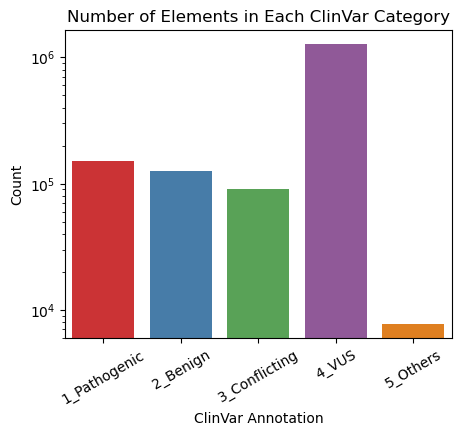

In [75]:
plot_by_cat(df_clinvar, "clinvar_clnsig_clean", title="Number of Elements in Each ClinVar Category")

# plot_by_cat(df_clinvar.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")!="3_Conflicting")),
#             "clinvar_clnsig_clean", title="")

# plot_by_cat(df_clinvar.filter(pl.col("ReviewStatus").is_in([
#                 'practice guideline'
#                 'reviewed by expert panel',
#                 'criteria provided, multiple submitters, no conflicts',
#                 'criteria provided, single submitter'
#             ])), "clinvar_clnsig_clean", title="")

### AI scores per ClinVar Variants 

In [51]:
def plot_ai_var_pred_dist(df, score_mapping, title):
    # Create a FacetGrid for multiple subplots
    fig, axes = plt.subplots(1, len(score_mapping.keys()), figsize=(len(score_mapping.keys())*5, 4.5)) ## , sharey=True
    hue_order = sorted(df["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
    # Loop through variables and create subplots
    for ax, var in zip(axes, score_mapping.keys()):
        sns.kdeplot(
            data=df,
            x=var,
            hue="clinvar_clnsig_clean",
            hue_order=hue_order,
            common_norm=False,
            ax=ax,
            palette="Set1"
        )
        ax.set_title(var)
    
    plt.suptitle(title, y=.96)    
    plt.tight_layout()
    plt.show()

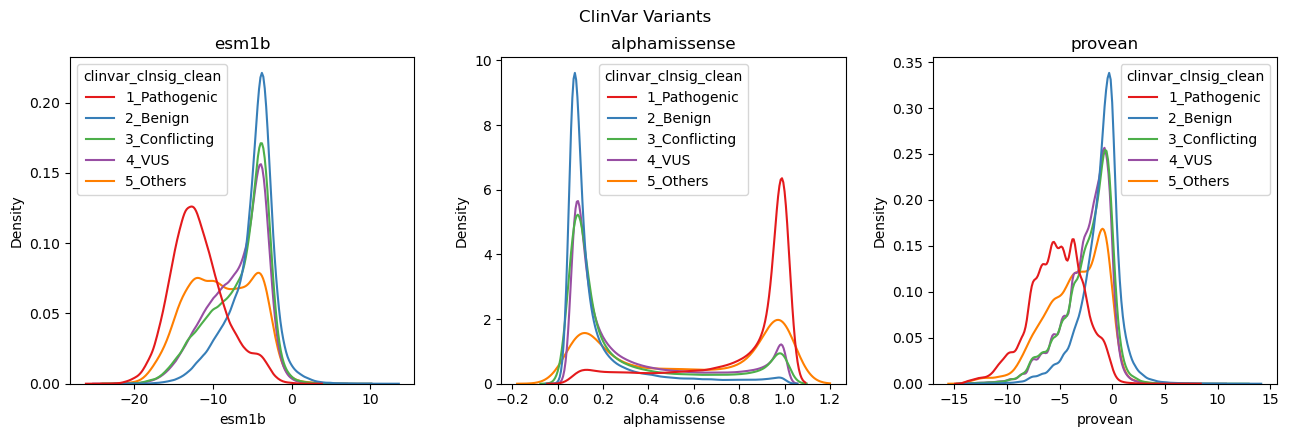

In [48]:
# Define the mapping from new column names to original column names
score_mapping = {
    "esm1b": "ESM1b_score",
    "alphamissense": "AlphaMissense_score",
    "provean": "PROVEAN_score"
}
predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

df_clinvar_sampled_plots = df_clinvar.with_columns(
    [
        pl.col(score_mapping[var])
          .replace(".", None)
          .cast(pl.Float64)
          .alias(var)
        for var in score_mapping.keys()
    ]
)
# .filter(
#     (pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others")
# )
# df_clinvar_sampled_plots

plot_ai_var_pred_dist(df_clinvar_sampled_plots.select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "ClinVar Variants")

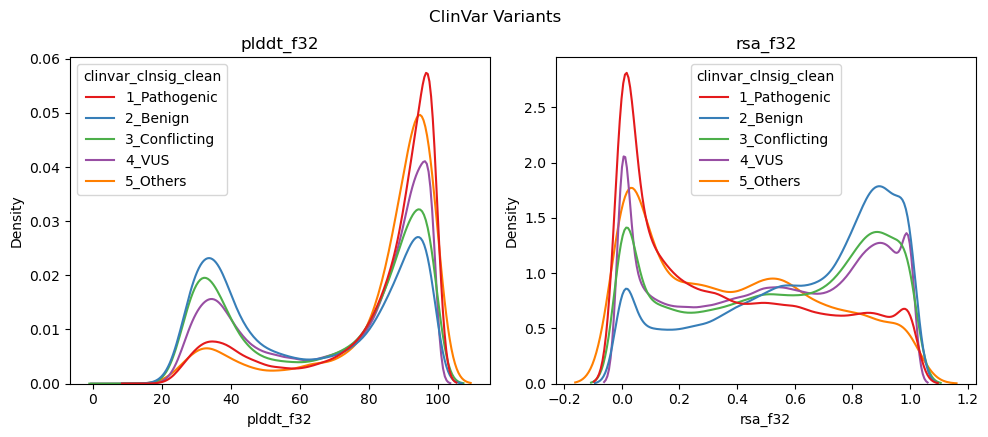

In [52]:
# Define the mapping from new column names to original column names
score_mapping = {
    "plddt_f32": "plddt",
    "rsa_f32": "rsa",
}

predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

df_clinvar_sampled_plots = df_clinvar.with_columns(
    [
        pl.col(score_mapping[var])
          .cast(pl.Float64)
          .alias(var)
        for var in score_mapping.keys()
    ]
)

plot_ai_var_pred_dist(df_clinvar_sampled_plots.select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "ClinVar Variants")

In [25]:
# plot_ai_var_pred_dist(df_clinvar_sampled_plots.filter(pl.col("ReviewStatus").is_in([
#                             'practice guideline'
#                             'reviewed by expert panel',
#                             'criteria provided, multiple submitters, no conflicts',
#                             'criteria provided, single submitter'
#                         ])).select(predictor_algos+list(score_mapping.keys())), 
#                       score_mapping, "All Benign & Pathogenic ClinVar Variants Strict Review Status")

In [26]:
# df_clinvar_sampled_plots.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")=="3_Conflicting")).select(predictor_algos+list(score_mapping.keys()))
# ## Among the Star>=2 variants, there is one conflicting variant, filter it out:
# plot_ai_var_pred_dist(df_clinvar_sampled_plots.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")!="3_Conflicting")).select(predictor_algos+list(score_mapping.keys())), 
#                       score_mapping, "All Benign & Pathogenic ClinVar Variants with StarStatus >= 2")

### VarChAMP Variants per ClinVar class

In [68]:
score_mapping = {
    "esm1b": "ESM1b_score",
    "alphamissense": "AlphaMissense_score",
    "provean": "PROVEAN_score"
}

varchamp_al_df_ai_plots = varchamp_al_df_ai_scores.with_columns(
    [
        pl.col(score_mapping[var])
          .replace(".", None)
          .cast(pl.Float64)
          .alias(var)
        for var in score_mapping.keys()
    ]
)

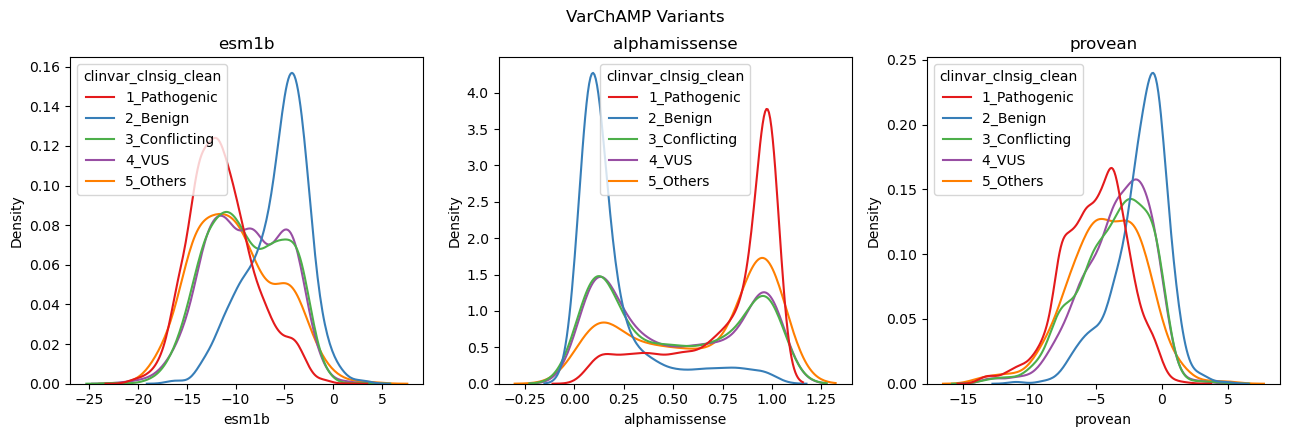

In [32]:
plot_ai_var_pred_dist(varchamp_al_df_ai_plots.select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "VarChAMP Variants")

__The distributions of AI VEP scores are not different between VarChAMP allele collection and the ClinVar variants across different ClinVar variant categories.__

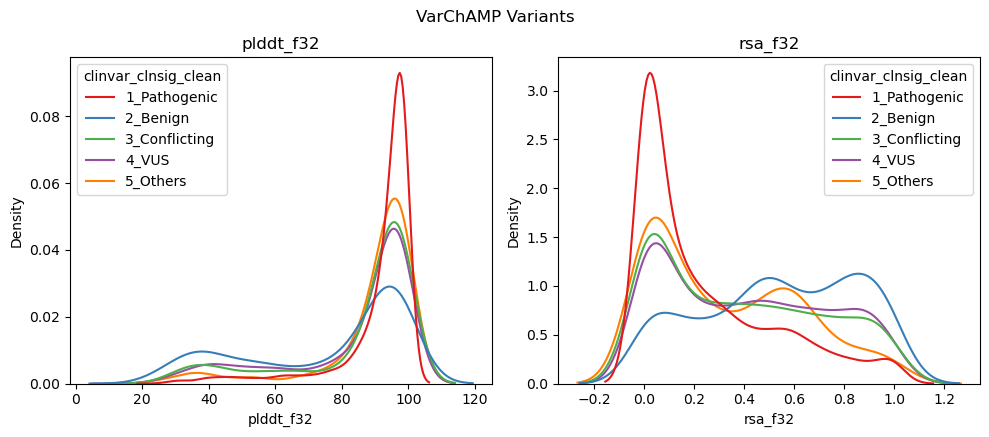

In [69]:
score_mapping = {
    "plddt_f32": "plddt",
    "rsa_f32": "rsa",
}

plot_ai_var_pred_dist(varchamp_al_df_ai_plots.select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "VarChAMP Variants")

__The distributions of protein structural scores like pLDDT from AF2 and Relative Solvent Accessability (RSA) are actually different between VarChAMP allele collection and the ClinVar variants across different ClinVar variant categories:__

* The VarChAMP allele collection has more confident local structures (less low-pLDDT variants);

* The VarChAMP allele collection has less alleles with higher RSA scores.